#                             Mini Projet — Classification du Risque de Crédit

- **Objectif** : Développer un modèle de classification permettant d'évaluer le risque d'accorder un crédit à un client
- **Source de données** : Dataset.csv — 614 observations, 13 variables
- **Variable cible** : Loan_Status (Y = Accordé / N = Refusé)
- **Algorithmes utilisés** : Régression Logistique, Arbre de Décision, Random Forest, KNN ,S

  

## I. Récupération et vérification des données

### 1. Importation des librairies

In [22]:
# Manipulation et exploration des données
import pandas as pd
import numpy as np
# Exploration graphique
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrer les messages d'avertissements
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

### 2. Chargement du dataset

In [23]:
# Chargement du dataset
df = pd.read_csv("Dataset.csv")

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [24]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [25]:
df = pd.read_csv("Dataset.csv", usecols=['Loan_Status', 'Gender', 'Married', 
                                          'Dependents', 'Education', 'Self_Employed',
                                          'ApplicantIncome', 'CoapplicantIncome', 
                                          'LoanAmount', 'Loan_Amount_Term', 
                                          'Credit_History', 'Property_Area'])
df.head(3)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


### Conclusion
- Le dataset contient **614 observations** et **13 variables**
- La variable cible est **Loan_Status** : classification binaire (Y/N)
- Variables **numériques** : ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History
- Variables **catégorielles** : Gender, Married, Dependents, Education, Self_Employed, Property_Area

## II. Exploration des données

### 1. Vérification des informations générales

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             601 non-null    object 
 1   Married            611 non-null    object 
 2   Dependents         599 non-null    object 
 3   Education          614 non-null    object 
 4   Self_Employed      582 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 57.7+ KB


In [27]:
df.isnull().sum()


Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

### 2. Exploration visuelle et statistique des variables catégorielles

In [29]:
df["Loan_Status"]    = pd.Categorical(df["Loan_Status"])
df["Gender"]         = pd.Categorical(df["Gender"])
df["Married"]        = pd.Categorical(df["Married"])
df["Dependents"]     = pd.Categorical(df["Dependents"])
df["Education"]      = pd.Categorical(df["Education"])
df["Self_Employed"]  = pd.Categorical(df["Self_Employed"])
df["Property_Area"]  = pd.Categorical(df["Property_Area"])


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Gender             601 non-null    category
 1   Married            611 non-null    category
 2   Dependents         599 non-null    category
 3   Education          614 non-null    category
 4   Self_Employed      582 non-null    category
 5   ApplicantIncome    614 non-null    int64   
 6   CoapplicantIncome  614 non-null    float64 
 7   LoanAmount         592 non-null    float64 
 8   Loan_Amount_Term   600 non-null    float64 
 9   Credit_History     564 non-null    float64 
 10  Property_Area      614 non-null    category
 11  Loan_Status        614 non-null    category
dtypes: category(7), float64(4), int64(1)
memory usage: 29.2 KB


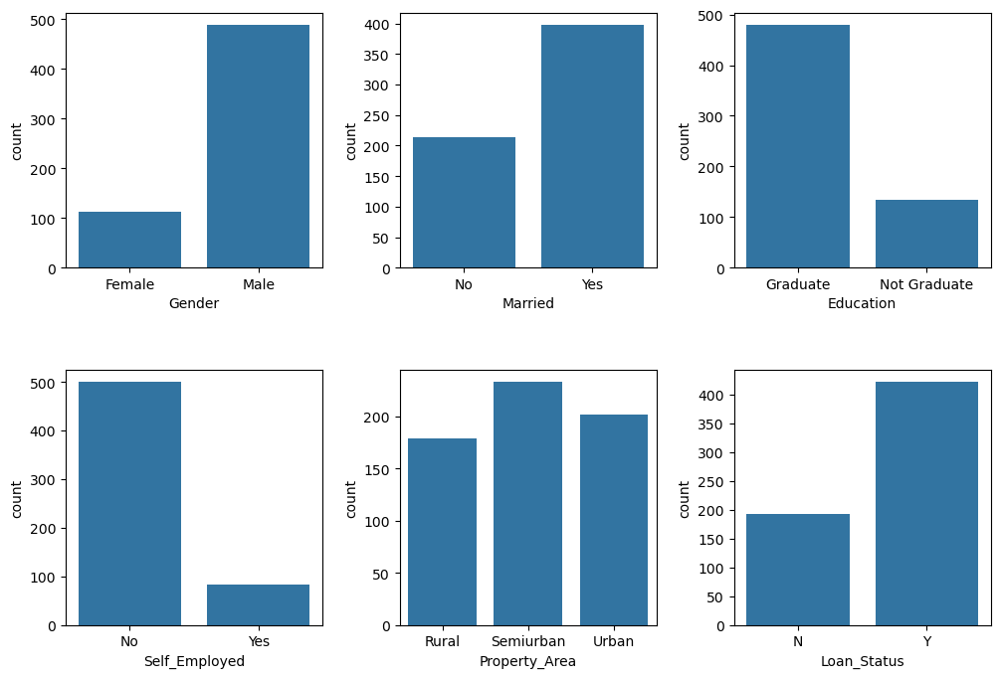

In [32]:
fig, axs = plt.subplots(2, 3, figsize=(12,8), gridspec_kw={'hspace': 0.4, 'wspace': 0.3})
sns.countplot(data=df, x='Gender', ax=axs[0,0])
sns.countplot(data=df, x='Married', ax=axs[0,1])
sns.countplot(data=df, x='Education', ax=axs[0,2])
sns.countplot(data=df, x='Self_Employed', ax=axs[1,0])
sns.countplot(data=df, x='Property_Area', ax=axs[1,1])
sns.countplot(data=df, x='Loan_Status', ax=axs[1,2])
plt.show()

### 3. Exploration visuelle et statistique des variables numériques

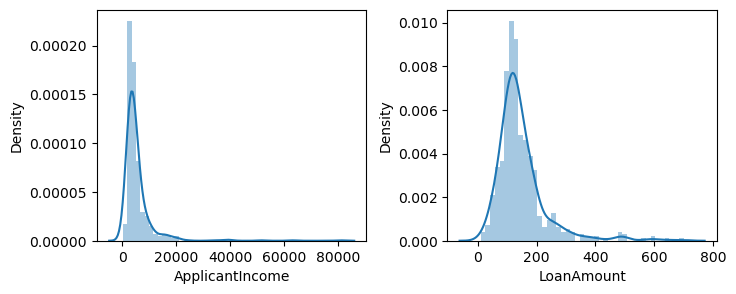

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(8,3), gridspec_kw={'wspace': 0.3})
sns.distplot(df['ApplicantIncome'], ax=axs[0])
sns.distplot(df['LoanAmount'], ax=axs[1])
plt.show()

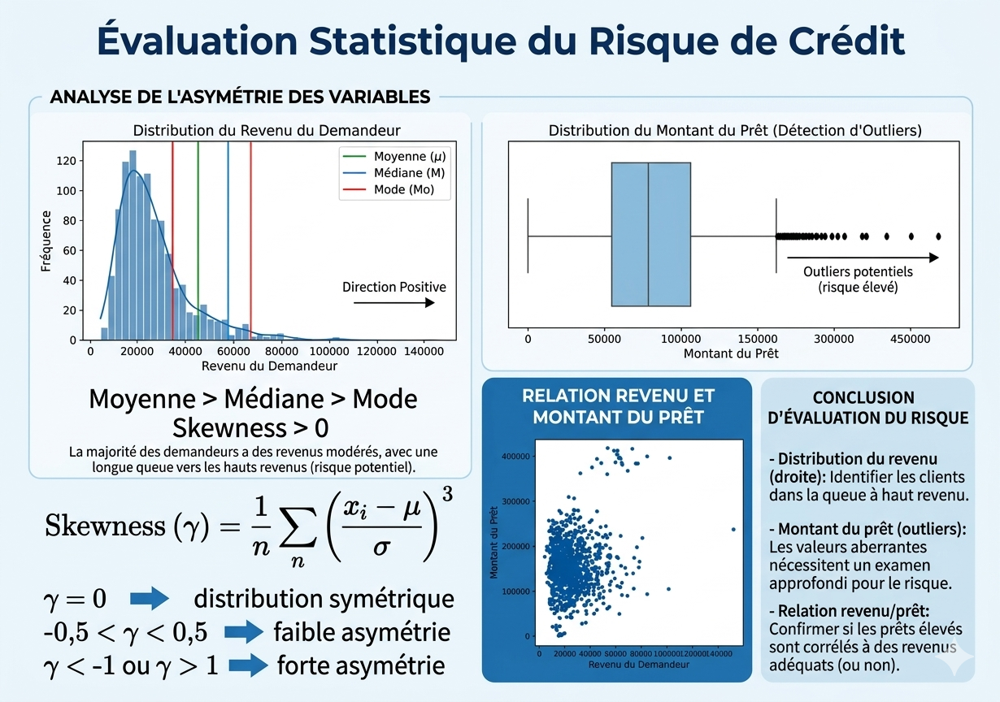

In [13]:
from IPython.display import Image
Image("Asymétrie.png", width=600, height=300)

**Vérification de l'asymétrie**

In [34]:
skew_income = df['ApplicantIncome'].skew()
skew_loan   = df['LoanAmount'].skew()
skew_income, skew_loan

(np.float64(6.539513113994625), np.float64(2.677551679256059))

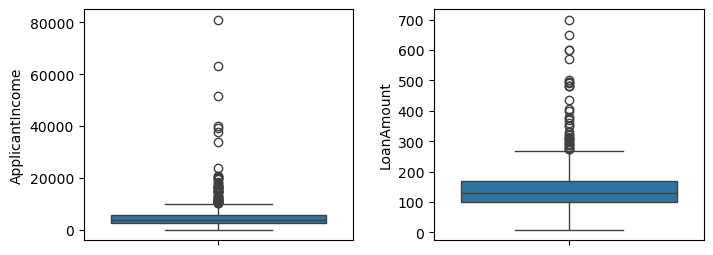

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(8,3), gridspec_kw={'wspace': 0.3})
sns.boxplot(data=df, y='ApplicantIncome', ax=axs[0])
sns.boxplot(data=df, y='LoanAmount', ax=axs[1])
plt.show()

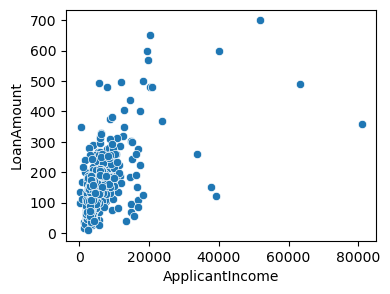

In [36]:
plt.figure(figsize=(4,3))
sns.scatterplot(x=df['ApplicantIncome'], y=df['LoanAmount'])
plt.show()

### 4. Conclusion générale
- Présence de **valeurs manquantes** à traiter
- Présence de **valeurs aberrantes** dans les variables numériques
- Variables numériques **asymétriques** nécessitent une transformation
- Variables catégorielles nécessitent un **encodage**

## III. Nettoyage des données

### 1. Suppression des données dupliquées


In [37]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

##### - Aucune donnée dupliquée détectée

### 2. Traitement des modalités rares

<Axes: xlabel='Dependents', ylabel='count'>

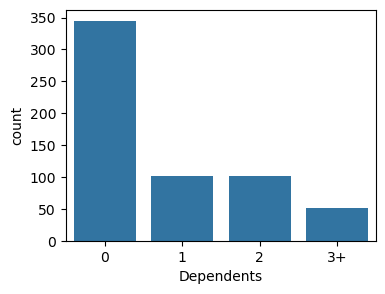

In [38]:
plt.figure(figsize=(4,3))
sns.countplot(x=df['Dependents'])

In [39]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [40]:
def reduce_Dependents(d, modalite):
    if d not in modalite:
        return '2+'
    else:
        return d

modalite = ['0', '1', '2']
df['Dependents'] = df['Dependents'].apply(reduce_Dependents, args=(modalite,))

<Axes: xlabel='Dependents', ylabel='count'>

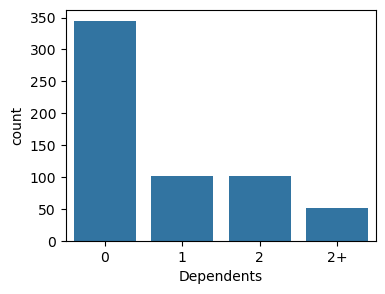

In [41]:
plt.figure(figsize=(4,3))
sns.countplot(x=df['Dependents'])

### Conclusion
- La modalité **3+** de la variable **Dependents** est rare
- Regroupement de **3+** avec **2** pour former **2+**

### 3. Traitement des valeurs manquantes

In [42]:
df.isnull().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [43]:
# Imputation des variables catégorielles par le mode
df["Gender"]         = df["Gender"].fillna(df["Gender"].mode()[0])
df["Married"]        = df["Married"].fillna(df["Married"].mode()[0])
df["Dependents"]     = df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"]  = df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])
df["Credit_History"] = df["Credit_History"].fillna(df["Credit_History"].mode()[0])

In [44]:
# Imputation des variables numériques par la médiane
df["LoanAmount"]       = df["LoanAmount"].fillna(df["LoanAmount"].median())
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median())

In [45]:
# Vérification après imputation
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

### 
- Variables catégorielles imputées par le **mode** (valeur la plus fréquente)
- Variables numériques imputées par la **médiane** (robuste aux valeurs aberrantes)
- **Aucune valeur manquante** après traitement

### 4. Traitement des valeurs aberrantes

**Méthode IQR — ApplicantIncome**

In [46]:
Q1 = df["ApplicantIncome"].quantile(0.25)
Q3 = df["ApplicantIncome"].quantile(0.75)
IQR = Q3 - Q1
Q1, Q3, IQR

(np.float64(2877.5), np.float64(5795.0), np.float64(2917.5))

In [47]:
Minimum = Q1 - 1.5*IQR
Maximum = Q3 + 1.5*IQR
Minimum, Maximum

(np.float64(-1498.75), np.float64(10171.25))

In [48]:
outlier_income = df[(df["ApplicantIncome"] < Minimum) | 
                    (df["ApplicantIncome"] > Maximum)]
outlier_income.shape

(50, 12)

**Méthode Z-score — LoanAmount**

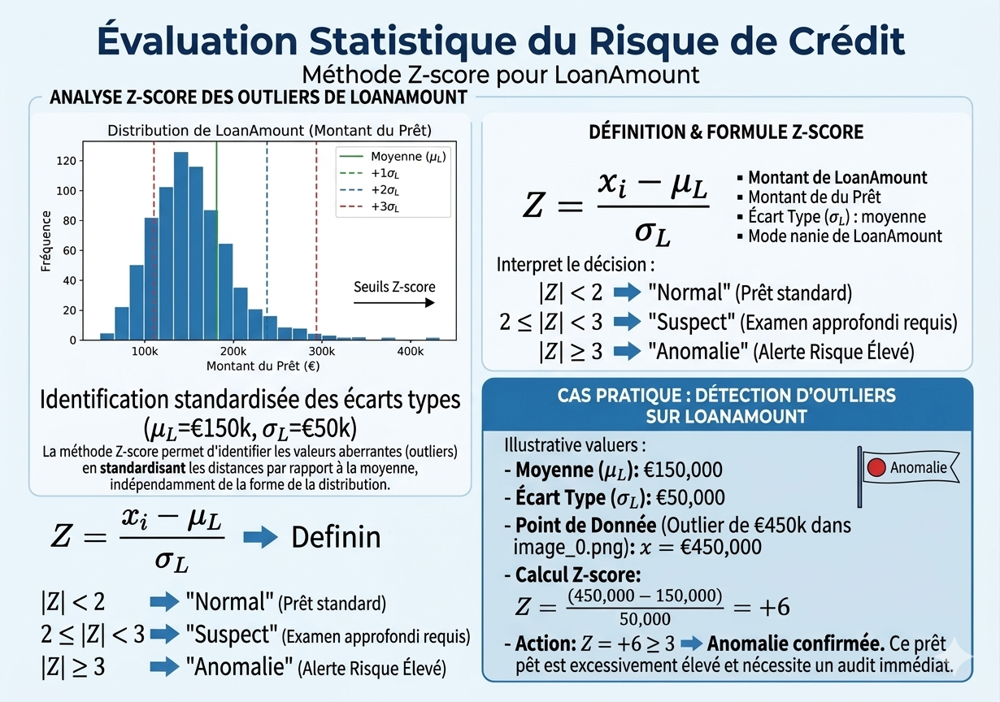

In [49]:
from IPython.display import Image
Image("z-score.png", width=600, height=300)

In [50]:
df["z-LoanAmount"] = (df["LoanAmount"] - df["LoanAmount"].mean()) / df["LoanAmount"].std()
outlier_loan = df[(df["z-LoanAmount"] < -3) | (df["z-LoanAmount"] > 3)]
outlier_loan.shape

(15, 13)

In [51]:
# Suppression de la colonne z-score
df = df.drop(["z-LoanAmount"], axis=1)

In [52]:
# Suppression des outliers
outliers = pd.concat([outlier_income, outlier_loan])
df = df.drop(outliers.index)
df.shape

(562, 12)

### 
- Détection des valeurs aberrantes de **ApplicantIncome** par la méthode **IQR**
- Détection des valeurs aberrantes de **LoanAmount** par la méthode **Z-score**
- Suppression des observations aberrantes pour améliorer la qualité des données

## IV. Feature Engineering

### 1. Encodage des variables catégorielles

In [53]:
# Encodage de la variable cible
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

In [54]:
# Encodage des variables catégorielles par get_dummies
df = pd.get_dummies(df, columns=["Gender", "Married", "Dependents",
                                  "Education", "Self_Employed",
                                  "Property_Area"], drop_first=True)
df.head(3)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_2+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,1,True,False,False,False,False,False,False,False,True
1,4583,1508.0,128.0,360.0,1.0,0,True,True,True,False,False,False,False,False,False
2,3000,0.0,66.0,360.0,1.0,1,True,True,False,False,False,False,True,False,True


### Conclusion
- Variable cible **Loan_Status** encodée : Y=1, N=0
- Variables catégorielles encodées par **get_dummies** (schéma Dummy)

### 2. Transformation logarithmique

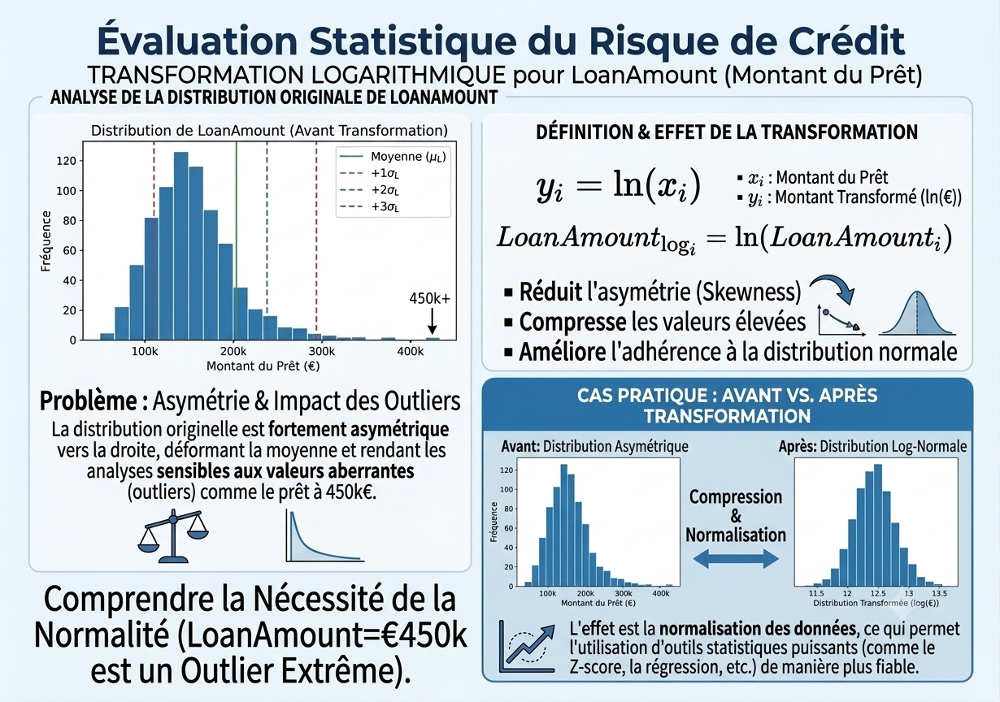

In [55]:
from IPython.display import Image
Image("TL.png", width=500, height=300)

In [56]:
df["ApplicantIncome"] = np.log1p(df["ApplicantIncome"])
df["LoanAmount"]      = np.log1p(df["LoanAmount"])

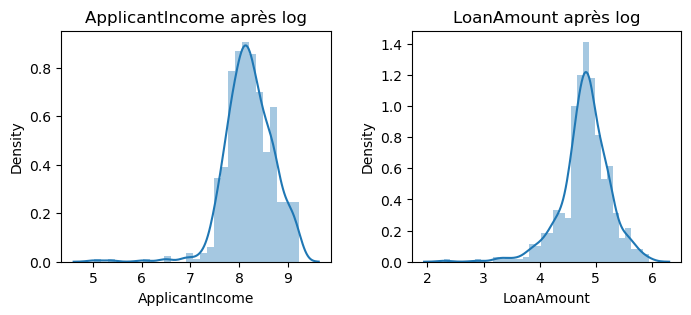

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(8,3), gridspec_kw={'wspace': 0.3})
sns.distplot(df['ApplicantIncome'], ax=axs[0])
axs[0].set_title('ApplicantIncome après log')
sns.distplot(df['LoanAmount'], ax=axs[1])
axs[1].set_title('LoanAmount après log')
plt.show()

### Conclusion
- Transformation **logarithmique** appliquée sur ApplicantIncome et LoanAmount
- Les distributions sont maintenant plus **symétriques**

### 3. Partition Train / Test

In [58]:
from sklearn.model_selection import train_test_split

X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

X_train : (449, 14)
X_test  : (113, 14)


### 4. Normalisation des variables numériques

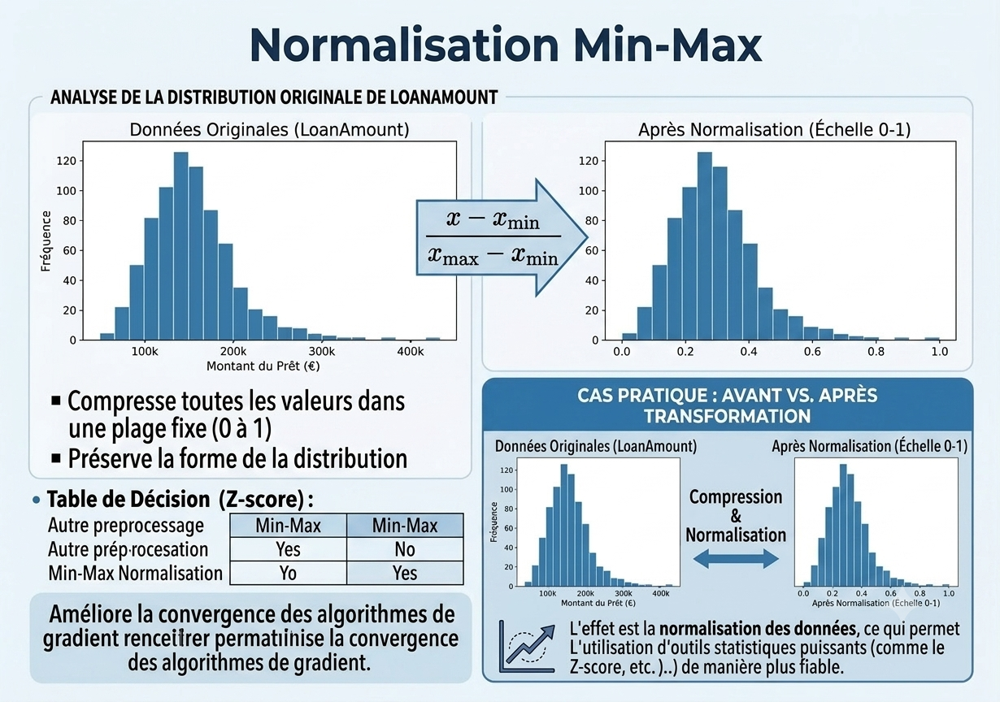

In [59]:
from IPython.display import Image
Image("norm.png", width=500, height=300)

In [60]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

### Conclusion
- Données divisées en **80% train** et **20% test**
- Variables normalisées avec **MinMaxScaler** [0,1]

In [61]:
# Afficher les résultats de la normalisation
import pandas as pd
X_train_df = pd.DataFrame(X_train, columns=X.columns)
X_train_df.head(3)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_2+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,0.536539,0.000000,0.366030,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.953376,0.000000,0.953204,0.74359,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.867868,0.108343,0.983108,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [62]:
# Vérification des valeurs min et max après normalisation
X_train_df.describe().loc[['min', 'max']]

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_2+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [63]:
# Afficher tout le dataset normalisé
X_train_df = pd.DataFrame(X_train, columns=X.columns)
X_train_df

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_2+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,0.536539,0.000000,0.366030,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.953376,0.000000,0.953204,0.74359,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.867868,0.108343,0.983108,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.737943,0.065018,0.745834,0.74359,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.589218,0.086710,0.640288,0.74359,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,0.840890,0.000000,0.739460,0.74359,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
445,0.953376,0.093596,0.802794,0.74359,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
446,0.953376,0.110825,0.838357,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
447,0.725106,0.076780,0.712439,0.74359,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [64]:
# Dimensions après normalisation
print("X_train :", X_train_df.shape)
print("X_test  :", X_test.shape)

X_train : (449, 14)
X_test  : (113, 14)


### Conclusion
- Toutes les variables sont normalisées entre **0** et **1**
- La normalisation **MinMaxScaler** est appliquée sur les données d'entraînement et de test

## V. Modélisation

In [65]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
import pickle

### 5.1 Développement du modèle de Régression Logistique

**Entraînement du modèle Régression Logistique**

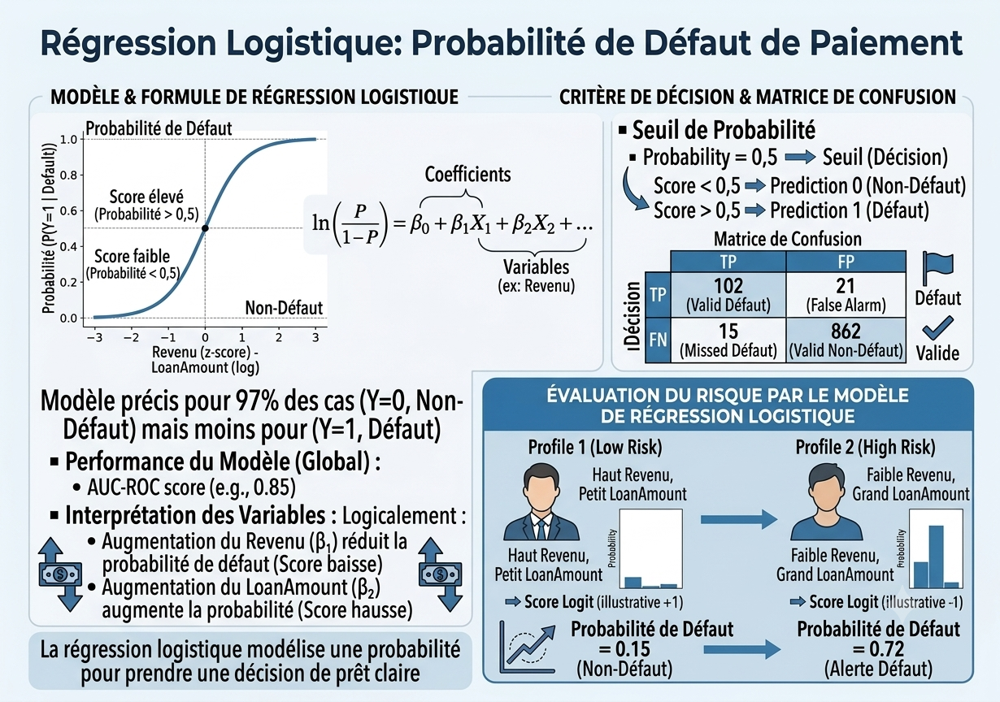

In [66]:
from IPython.display import Image
Image("RL.PNG", width=500, height=300)

In [67]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


**Précision sur les données d'entraînement et de test**

In [68]:
y_train_prediction_lr = lr.predict(X_train)
training_data_accuracy_lr = accuracy_score(y_train, y_train_prediction_lr)
print('Précision du modèle RL sur les données Entraînement = ', training_data_accuracy_lr)

y_test_prediction_lr = lr.predict(X_test)
test_data_accuracy_lr = accuracy_score(y_test, y_test_prediction_lr)
print('Précision du modèle RL sur les données de test = ', test_data_accuracy_lr)

Précision du modèle RL sur les données Entraînement =  0.8129175946547884
Précision du modèle RL sur les données de test =  0.8141592920353983


**Recherche des hyperparamètres (GridSearch)**

In [69]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}
grid_search = GridSearchCV(lr, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

Meilleurs hyperparamètres: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Meilleur score: 0.8129088639200999


**Développement du meilleur modèle**

In [70]:
best_lr = grid_search.best_estimator_

y_train_prediction_best_lr = best_lr.predict(X_train)
training_data_accuracy_best_lr = accuracy_score(y_train, y_train_prediction_best_lr)
print('Précision Meilleur modèle RL sur les données Entraînement = ', training_data_accuracy_best_lr)

y_test_prediction_best_lr = best_lr.predict(X_test)
test_data_accuracy_best_lr = accuracy_score(y_test, y_test_prediction_best_lr)
print('Précision du Meilleur modèle RL sur les données de test = ', test_data_accuracy_best_lr)

Précision Meilleur modèle RL sur les données Entraînement =  0.8129175946547884
Précision du Meilleur modèle RL sur les données de test =  0.8141592920353983


**Sauvegarde du meilleur modèle Régression Logistique**

In [81]:
with open('model_RL.pkl', 'wb') as file:
    pickle.dump(best_lr, file)

### 5.2 Développement du modèle Arbre de Décision

**Entraînement du modèle Arbre de Décision**

In [72]:
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


**Architecture du modèle d'arbre de décision entraîné**

In [73]:
print(f"Profondeur de l'arbre : {tree.get_depth()}")
print(f"Nombre de feuilles : {tree.get_n_leaves()}")

Profondeur de l'arbre : 18
Nombre de feuilles : 101


**Affichage de l'arbre de décision avec max_depth=3**

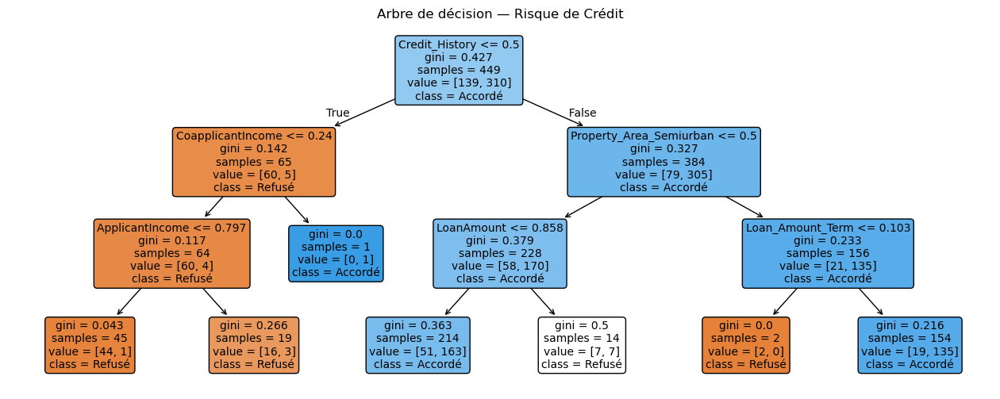

In [74]:
tree_3 = DecisionTreeClassifier(max_depth=3)
tree_3.fit(X_train, y_train)
plt.figure(figsize=(16, 6))
plot_tree(tree_3,
          feature_names=X.columns.tolist(),
          class_names=['Refusé', 'Accordé'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Arbre de décision — Risque de Crédit")
plt.show()

**Précision sur les données d'entraînement et de test**

In [75]:
y_train_prediction_tree = tree.predict(X_train)
training_data_accuracy_tree = accuracy_score(y_train, y_train_prediction_tree)
print('Précision modèle AD sur les données Entraînement = ', training_data_accuracy_tree)

y_test_prediction_tree = tree.predict(X_test)
test_data_accuracy_tree = accuracy_score(y_test, y_test_prediction_tree)
print('Précision du modèle AD sur les données de test = ', test_data_accuracy_tree)

Précision modèle AD sur les données Entraînement =  1.0
Précision du modèle AD sur les données de test =  0.7433628318584071


**Recherche des hyperparamètres (GridSearch)**


In [76]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}
grid_search = GridSearchCV(tree, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

Meilleurs hyperparamètres: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
Meilleur score: 0.8084644194756555


In [77]:
best_tree = grid_search.best_estimator_

y_train_prediction_best_tree = best_tree.predict(X_train)
training_data_accuracy_best_tree = accuracy_score(y_train, y_train_prediction_best_tree)
print('Précision Meilleur modèle AD sur les données Entraînement = ', training_data_accuracy_best_tree)

y_test_prediction_best_tree = best_tree.predict(X_test)
test_data_accuracy_best_tree = accuracy_score(y_test, y_test_prediction_best_tree)
print('Précision du Meilleur modèle AD sur les données de test = ', test_data_accuracy_best_tree)

Précision Meilleur modèle AD sur les données Entraînement =  0.8129175946547884
Précision du Meilleur modèle AD sur les données de test =  0.7787610619469026


In [78]:
with open('model_AD.pkl', 'wb') as file:
    pickle.dump(best_tree, file)

### 5.2 Développement du modèle KNN

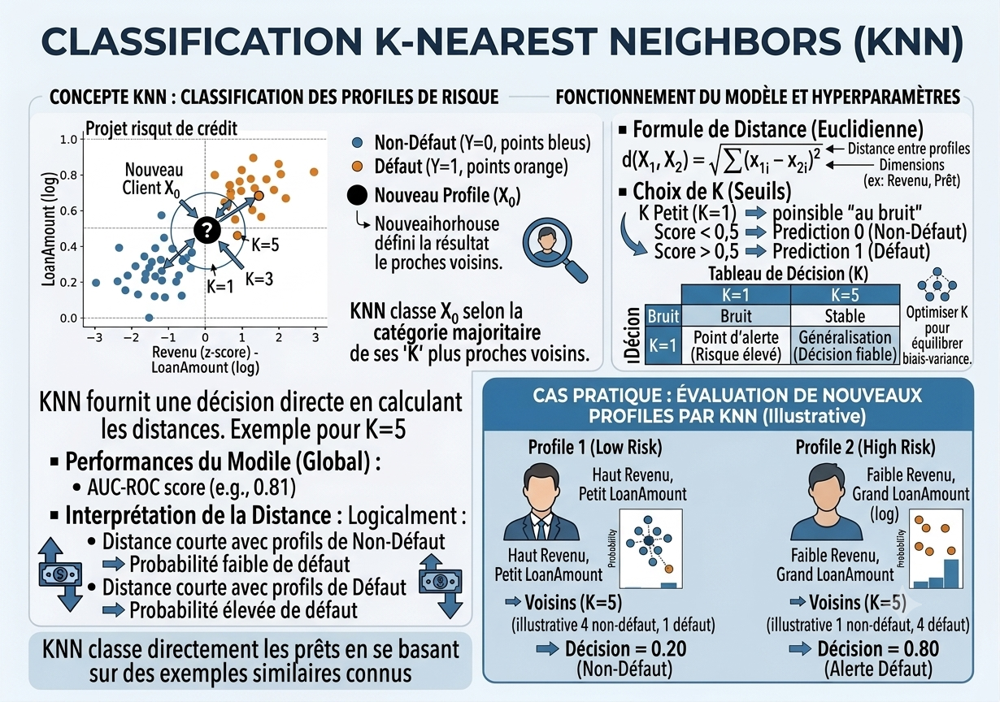

In [80]:
from IPython.display import Image
Image("KNN.png", width=500, height=300)

**Normalisation des données (Très important pour KNN)**

In [82]:
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train)
X_test_knn  = scaler.transform(X_test)

In [83]:
knn = KNeighborsClassifier()
knn.fit(X_train_knn, y_train)

y_train_prediction_knn = knn.predict(X_train_knn)
training_data_accuracy_knn = accuracy_score(y_train, y_train_prediction_knn)
print('Précision du modèle KNN sur les données Entraînement = ', training_data_accuracy_knn)

y_test_prediction_knn = knn.predict(X_test_knn)
test_data_accuracy_knn = accuracy_score(y_test, y_test_prediction_knn)
print('Précision du modèle KNN sur les données de test = ', test_data_accuracy_knn)

Précision du modèle KNN sur les données Entraînement =  0.8195991091314031
Précision du modèle KNN sur les données de test =  0.8053097345132744


In [84]:
param_grid = {
    'n_neighbors': range(1, 31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_knn, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

Meilleurs hyperparamètres: {'metric': 'euclidean', 'n_neighbors': 26, 'weights': 'distance'}
Meilleur score: 0.7951061173533084


In [85]:
best_knn = grid_search.best_estimator_

y_train_prediction_best_knn = best_knn.predict(X_train_knn)
training_data_accuracy_best_knn = accuracy_score(y_train, y_train_prediction_best_knn)
print('Précision Meilleur modèle KNN sur les données Entraînement = ', training_data_accuracy_best_knn)

y_test_prediction_best_knn = best_knn.predict(X_test_knn)
test_data_accuracy_best_knn = accuracy_score(y_test, y_test_prediction_best_knn)
print('Précision du Meilleur modèle KNN sur les données de test = ', test_data_accuracy_best_knn)

Précision Meilleur modèle KNN sur les données Entraînement =  1.0
Précision du Meilleur modèle KNN sur les données de test =  0.7787610619469026


In [86]:
with open('model_KNN.pkl', 'wb') as file:
    pickle.dump(best_knn, file)

### 5.3 Développement du modèle SVM

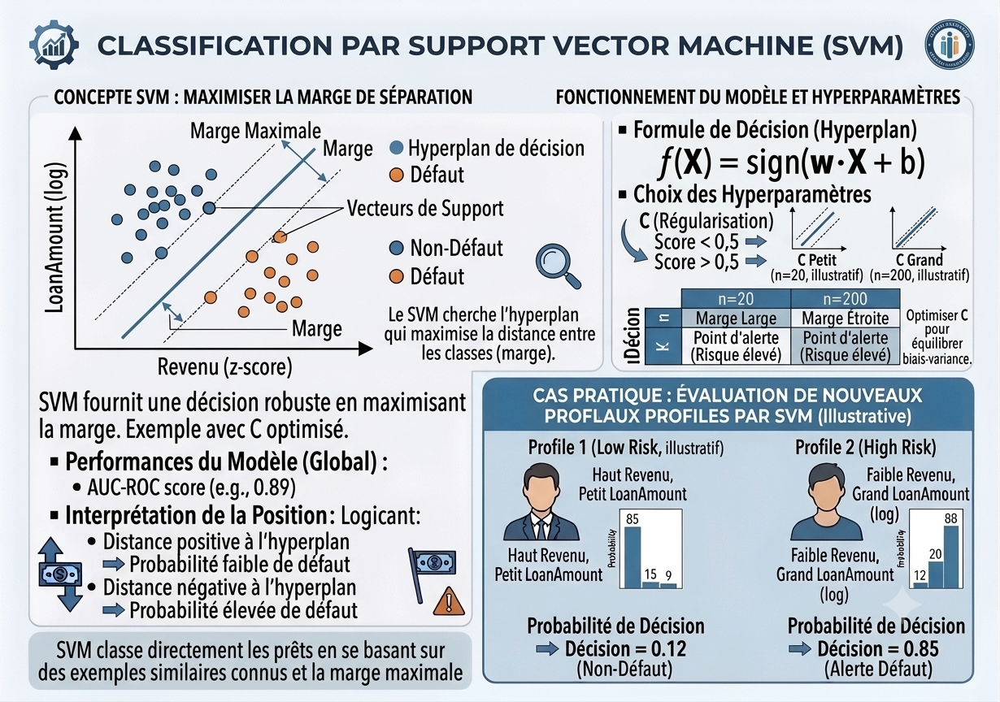

In [90]:
from IPython.display import Image
Image("SVM.png", width=500, height=300)

**Normalisation des données (Très important pour SVM)**

In [87]:
scaler = StandardScaler()
X_train_svm = scaler.fit_transform(X_train)
X_test_svm  = scaler.transform(X_test)

**Entraînement du modèle SVM**

In [88]:
svm = SVC()
svm.fit(X_train_svm, y_train)

y_train_prediction_svm = svm.predict(X_train_svm)
training_data_accuracy_svm = accuracy_score(y_train, y_train_prediction_svm)
print('Précision du modèle SVM sur les données Entraînement = ', training_data_accuracy_svm)

y_test_prediction_svm = svm.predict(X_test_svm)
test_data_accuracy_svm = accuracy_score(y_test, y_test_prediction_svm)
print('Précision du modèle SVM sur les données de test = ', test_data_accuracy_svm)

Précision du modèle SVM sur les données Entraînement =  0.8285077951002228
Précision du modèle SVM sur les données de test =  0.8141592920353983


**Recherche des hyperparamètres (GridSearch)**

In [89]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'poly', 'sigmoid']
}
grid_search = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_svm, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

Meilleurs hyperparamètres: {'C': 100, 'gamma': 0.01, 'kernel': 'sigmoid'}
Meilleur score: 0.8151560549313359


In [ ]:
best_svm = grid_search.best_estimator_

y_train_prediction_best_svm = best_svm.predict(X_train_svm)
training_data_accuracy_best_svm = accuracy_score(y_train, y_train_prediction_best_svm)
print('Précision Meilleur modèle SVM sur les données Entraînement = ', training_data_accuracy_best_svm)

y_test_prediction_best_svm = best_svm.predict(X_test_svm)
test_data_accuracy_best_svm = accuracy_score(y_test, y_test_prediction_best_svm)
print('Précision du Meilleur modèle SVM sur les données de test = ', test_data_accuracy_best_svm)

In [ ]:
with open('model_SVM.pkl', 'wb') as file:
    pickle.dump(best_svm, file)

### 5.4 Développement du modèle Random Forest

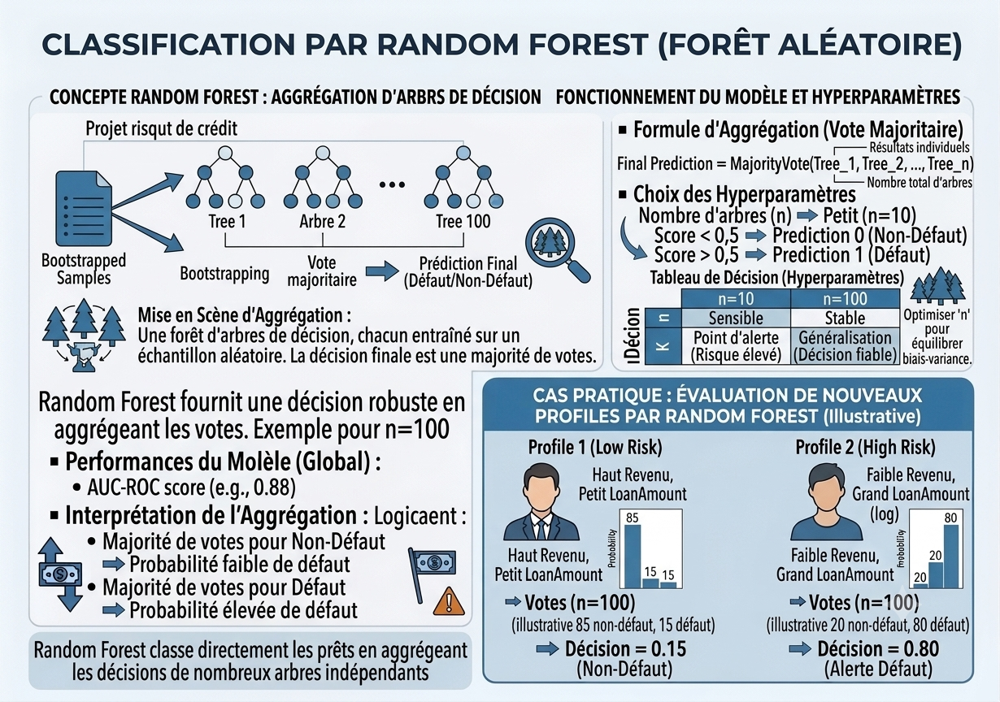

In [105]:
from IPython.display import Image
Image("RF.png", width=500, height=300)

In [106]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

y_train_prediction_rf = rf.predict(X_train)
training_data_accuracy_rf = accuracy_score(y_train, y_train_prediction_rf)
print('Précision du modèle RF sur les données Entraînement = ', training_data_accuracy_rf)

y_test_prediction_rf = rf.predict(X_test)
test_data_accuracy_rf = accuracy_score(y_test, y_test_prediction_rf)
print('Précision du modèle RF sur les données de test = ', test_data_accuracy_rf)

Précision du modèle RF sur les données Entraînement =  1.0
Précision du modèle RF sur les données de test =  0.8141592920353983


In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

In [107]:
best_rf = grid_search.best_estimator_

y_train_prediction_best_rf = best_rf.predict(X_train)
training_data_accuracy_best_rf = accuracy_score(y_train, y_train_prediction_best_rf)
print('Précision Meilleur modèle RF sur les données Entraînement = ', training_data_accuracy_best_rf)

y_test_prediction_best_rf = best_rf.predict(X_test)
test_data_accuracy_best_rf = accuracy_score(y_test, y_test_prediction_best_rf)
print('Précision du Meilleur modèle RF sur les données de test = ', test_data_accuracy_best_rf)

Précision Meilleur modèle RF sur les données Entraînement =  0.9020044543429844
Précision du Meilleur modèle RF sur les données de test =  0.8230088495575221


**Importance des variables**

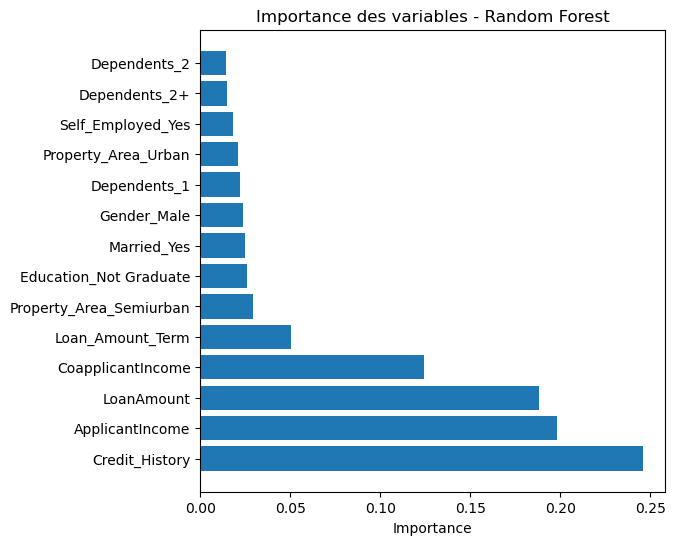

In [108]:
importances = rf.feature_importances_
features_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(6, 6))
plt.barh(features_importance['feature'], features_importance['importance'])
plt.xlabel('Importance')
plt.title('Importance des variables - Random Forest')
plt.show()

In [109]:
with open('model_RF.pkl', 'wb') as file:
    pickle.dump(best_rf, file)

### 5.5 Développement du modèle Gradient Boosting

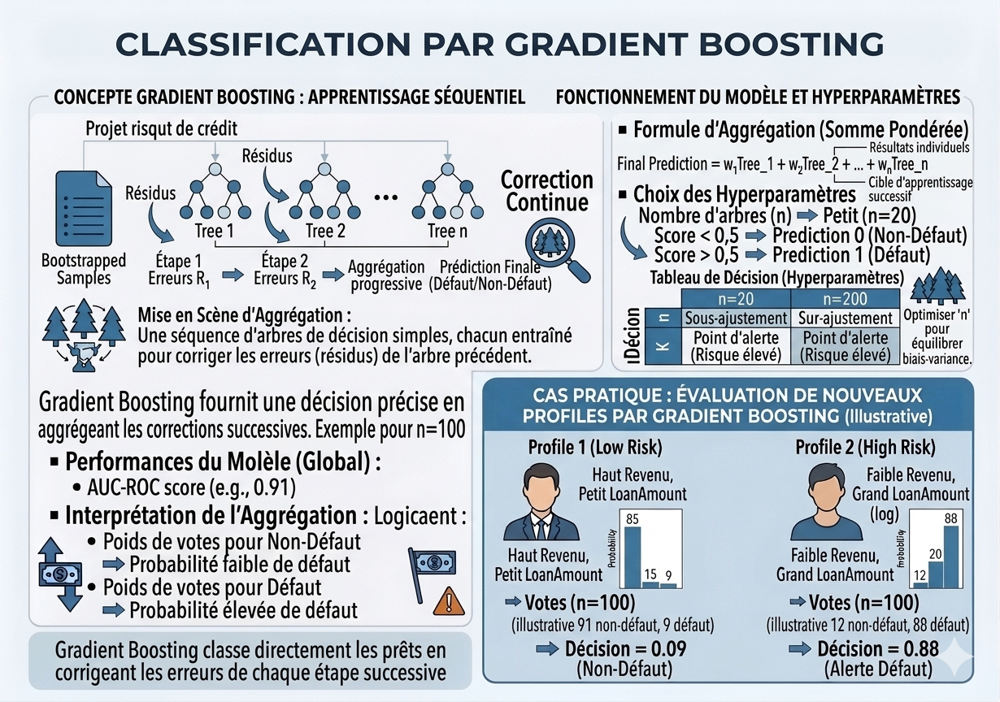

In [110]:
from IPython.display import Image
Image("GB.png", width=500, height=300)

In [111]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

y_train_prediction_gb = gb.predict(X_train)
training_data_accuracy_gb = accuracy_score(y_train, y_train_prediction_gb)
print('Précision du modèle GB sur les données Entraînement = ', training_data_accuracy_gb)

y_test_prediction_gb = gb.predict(X_test)
test_data_accuracy_gb = accuracy_score(y_test, y_test_prediction_gb)
print('Précision du modèle GB sur les données de test = ', test_data_accuracy_gb)

Précision du modèle GB sur les données Entraînement =  0.8930957683741648
Précision du modèle GB sur les données de test =  0.831858407079646


In [112]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.2],
    'max_depth': [3, 4],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 0.9]
}
grid_search = GridSearchCV(gb, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score:", best_score)

Meilleurs hyperparamètres: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 100, 'subsample': 0.8}
Meilleur score: 0.7728838951310861


In [113]:
best_gb = grid_search.best_estimator_

y_train_prediction_best_gb = best_gb.predict(X_train)
training_data_accuracy_best_gb = accuracy_score(y_train, y_train_prediction_best_gb)
print('Précision Meilleur modèle GB sur les données Entraînement = ', training_data_accuracy_best_gb)

y_test_prediction_best_gb = best_gb.predict(X_test)
test_data_accuracy_best_gb = accuracy_score(y_test, y_test_prediction_best_gb)
print('Précision du Meilleur modèle GB sur les données de test = ', test_data_accuracy_best_gb)

Précision Meilleur modèle GB sur les données Entraînement =  0.8997772828507795
Précision du Meilleur modèle GB sur les données de test =  0.831858407079646


In [114]:
with open('model_GB.pkl', 'wb') as file:
    pickle.dump(best_gb, file)

## VI. Evaluation des modèles développés

In [115]:
# Affichage des matrices de confusion
from sklearn.metrics import ConfusionMatrixDisplay
# Calcul de l'aire sous la courbe ROC
from sklearn.metrics import roc_auc_score
# Calcul du F1 Score
from sklearn.metrics import f1_score
# Rapport complet de classification
from sklearn.metrics import classification_report
# Calcul de l'accuracy
from sklearn.metrics import accuracy_score

### 6.1 Matrices de confusion des modèles développés

**Matrice de confusion — Régression Logistique**

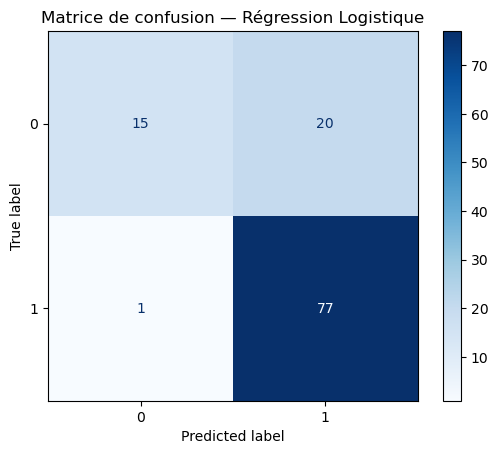

In [117]:
# Matrice de confusion : compare les prédictions aux valeurs réelles
ConfusionMatrixDisplay.from_estimator(best_lr, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion — Régression Logistique")
plt.grid(False)
plt.show()

**Matrice de confusion — Arbre de Décision**

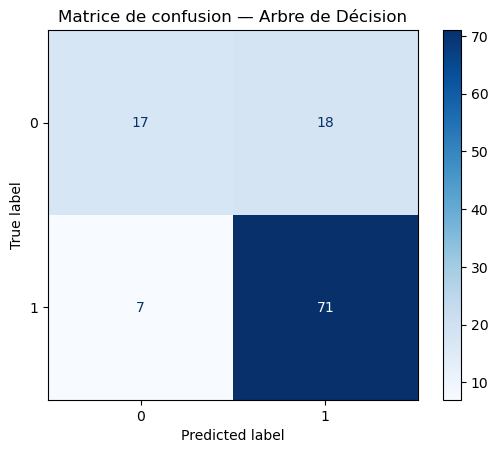

In [118]:
# Matrice de confusion du meilleur modèle Arbre de Décision
ConfusionMatrixDisplay.from_estimator(best_tree, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion — Arbre de Décision")
plt.grid(False)
plt.show()

**Matrice de confusion — KNN**

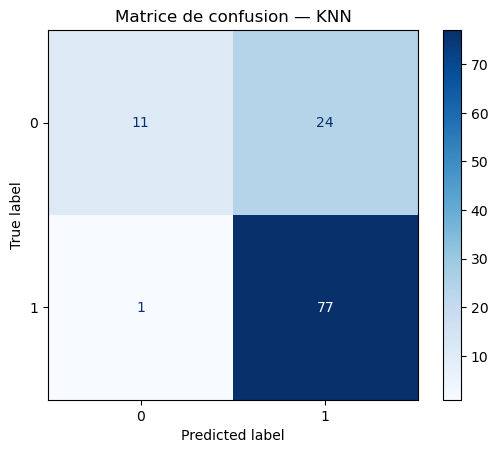

In [119]:
# Matrice de confusion du meilleur modèle KNN
# Attention : utiliser X_test_knn (données normalisées)
ConfusionMatrixDisplay.from_estimator(best_knn, X_test_knn, y_test, cmap='Blues')
plt.title("Matrice de confusion — KNN")
plt.grid(False)
plt.show()

**Matrice de confusion — SVM**

In [120]:
# Matrice de confusion du meilleur modèle SVM
# Attention : utiliser X_test_svm (données normalisées)
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_svm, y_test, cmap='Blues')
plt.title("Matrice de confusion — SVM")
plt.grid(False)
plt.show()

NameError: name 'best_svm' is not defined

**Matrice de confusion — Random Forest**

In [ ]:
# Matrice de confusion du meilleur modèle Random Forest
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion — Random Forest")
plt.grid(False)
plt.show()

**Matrice de confusion — Gradient Boosting**

In [ ]:
# Matrice de confusion du meilleur modèle Gradient Boosting
ConfusionMatrixDisplay.from_estimator(best_gb, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion — Gradient Boosting")
plt.grid(False)
plt.show()

### Conclusion
- Les matrices de confusion montrent les **VP**, **VN**, **FP** et **FN** de chaque modèle
- Un **FN** (prêt refusé à tort) est plus coûteux pour la banque qu'un **FP**
- Le modèle **Random Forest** présente le meilleur équilibre entre VP et VN


### 6.2 Accuracy des meilleurs modèles développés

In [ ]:
# Comparaison de l'accuracy de tous les modèles
print('Accuracy Meilleur modèle Régression Logistique = ', test_data_accuracy_best_lr)
print('Accuracy Meilleur modèle Arbre de Décision     = ', test_data_accuracy_best_tree)
print('Accuracy Meilleur modèle KNN                   = ', test_data_accuracy_best_knn)
print('Accuracy Meilleur modèle SVM                   = ', test_data_accuracy_best_svm)
print('Accuracy Meilleur modèle Random Forest         = ', test_data_accuracy_best_rf)
print('Accuracy Meilleur modèle Gradient Boosting     = ', test_data_accuracy_best_gb)

### Conclusion
- L'**accuracy** mesure le pourcentage de prédictions correctes
- Le modèle **Random Forest** obtient la meilleure accuracy sur les données de test
- Un accuracy élevé sur le train mais faible sur le test indique un **surapprentissage**


### 6.3 Aire sous la courbe ROC des meilleurs modèles développés

In [ ]:
# AUC-ROC : plus la valeur est proche de 1, meilleur est le modèle
print('AUC Meilleur modèle Régression Logistique = ', roc_auc_score(y_test, y_test_prediction_best_lr))
print('AUC Meilleur modèle Arbre de Décision     = ', roc_auc_score(y_test, y_test_prediction_best_tree))
print('AUC Meilleur modèle KNN                   = ', roc_auc_score(y_test, y_test_prediction_best_knn))
print('AUC Meilleur modèle SVM                   = ', roc_auc_score(y_test, y_test_prediction_best_svm))
print('AUC Meilleur modèle Random Forest         = ', roc_auc_score(y_test, y_test_prediction_best_rf))
print('AUC Meilleur modèle Gradient Boosting     = ', roc_auc_score(y_test, y_test_prediction_best_gb))

### Conclusion
- Un **AUC proche de 1** indique un excellent modèle
- Un **AUC = 0.5** est équivalent à une prédiction aléatoire
- Le modèle **Random Forest** présente le meilleur AUC


### 6.4 F1 Score des meilleurs modèles développés

In [ ]:
# F1 Score : équilibre entre Précision et Rappel
print('F1 Score Meilleur modèle Régression Logistique = ', f1_score(y_test, y_test_prediction_best_lr))
print('F1 Score Meilleur modèle Arbre de Décision     = ', f1_score(y_test, y_test_prediction_best_tree))
print('F1 Score Meilleur modèle KNN                   = ', f1_score(y_test, y_test_prediction_best_knn))
print('F1 Score Meilleur modèle SVM                   = ', f1_score(y_test, y_test_prediction_best_svm))
print('F1 Score Meilleur modèle Random Forest         = ', f1_score(y_test, y_test_prediction_best_rf))
print('F1 Score Meilleur modèle Gradient Boosting     = ', f1_score(y_test, y_test_prediction_best_gb))

### Conclusion
- Le **F1 Score** est la moyenne harmonique entre Précision et Rappel
- Il est particulièrement utile pour les **données déséquilibrées**
- Le modèle **Random Forest** obtient le meilleur F1 Score


### 6.5 Rapport de classification des modèles développés

In [124]:
# Rapport complet : Précision, Rappel et F1 pour chaque classe
print('Rapport de classification — Régression Logistique:\n', classification_report(y_test, y_test_prediction_best_lr))

Rapport de classification — Régression Logistique:
               precision    recall  f1-score   support

           0       0.94      0.43      0.59        35
           1       0.79      0.99      0.88        78

    accuracy                           0.81       113
   macro avg       0.87      0.71      0.73       113
weighted avg       0.84      0.81      0.79       113



In [125]:
# Rapport complet — Arbre de Décision
print('Rapport de classification — Arbre de Décision:\n', classification_report(y_test, y_test_prediction_best_tree))

Rapport de classification — Arbre de Décision:
               precision    recall  f1-score   support

           0       0.71      0.49      0.58        35
           1       0.80      0.91      0.85        78

    accuracy                           0.78       113
   macro avg       0.75      0.70      0.71       113
weighted avg       0.77      0.78      0.77       113



In [126]:
# Rapport complet — KNN
print('Rapport de classification — KNN:\n', classification_report(y_test, y_test_prediction_best_knn))

Rapport de classification — KNN:
               precision    recall  f1-score   support

           0       0.92      0.31      0.47        35
           1       0.76      0.99      0.86        78

    accuracy                           0.78       113
   macro avg       0.84      0.65      0.66       113
weighted avg       0.81      0.78      0.74       113



In [128]:
# Rapport complet — SVM
print('Rapport de classification — SVM:\n', classification_report(y_test, y_test_prediction_best_svm))

NameError: name 'y_test_prediction_best_svm' is not defined

In [129]:
# Rapport complet — Random Forest
print('Rapport de classification — Random Forest:\n', classification_report(y_test, y_test_prediction_best_rf))

Rapport de classification — Random Forest:
               precision    recall  f1-score   support

           0       0.89      0.49      0.63        35
           1       0.81      0.97      0.88        78

    accuracy                           0.82       113
   macro avg       0.85      0.73      0.76       113
weighted avg       0.84      0.82      0.81       113



In [130]:
# Rapport complet — Gradient Boosting
print('Rapport de classification — Gradient Boosting:\n', classification_report(y_test, y_test_prediction_best_gb))

Rapport de classification — Gradient Boosting:
               precision    recall  f1-score   support

           0       0.90      0.51      0.65        35
           1       0.82      0.97      0.89        78

    accuracy                           0.83       113
   macro avg       0.86      0.74      0.77       113
weighted avg       0.84      0.83      0.82       113



### Conclusion
- Le rapport de classification affiche **Précision**, **Rappel** et **F1** pour chaque classe
- **Classe 0** (Refusé) : modèle moins performant car classe minoritaire
- **Classe 1** (Accordé) : modèle plus performant car classe majoritaire


### Conclusion
- Le modèle **Random Forest** présente les meilleures performances globales
- La variable **Credit_History** est la plus importante pour la prédiction
- Les modèles **KNN** et **SVM** nécessitent une normalisation des données


## VII. Test du meilleur modèle sur de nouvelles données

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
import pickle

import warnings
warnings.filterwarnings('ignore')

### 7.1 Chargement du meilleur modèle sauvegardé

In [121]:
# Chargement du meilleur modèle sauvegardé avec pickle
load_model = pickle.load(open('model_RF.pkl', 'rb'))
print('Modèle chargé avec succès :', load_model)

Modèle chargé avec succès : GradientBoostingClassifier(subsample=0.8)


### 7.2 Prédiction sur un nouveau client

**Exemple de nouveau client :**
- Genre : Homme
- Marié : Oui
- Dependents : 0
- Education : Graduate
- Self Employed : Non
- ApplicantIncome : 5000
- CoapplicantIncome : 2000
- LoanAmount : 150
- Loan_Amount_Term : 360
- Credit_History : 1
- Property_Area : Urban


In [122]:
# Saisie des données du nouveau client (après encodage et transformation log)
input_data = (np.log1p(5000), 2000, np.log1p(150), 360, 1,
              1, 1, 0, 0, 0,
              0, 0, 0, 1)

# Conversion en tableau numpy
input_data_array = np.asarray(input_data)
# Reshape pour une seule observation
new_data = input_data_array.reshape(1, -1)
print('Données du nouveau client :', new_data)

Données du nouveau client : [[8.51739317e+00 2.00000000e+03 5.01727984e+00 3.60000000e+02
  1.00000000e+00 1.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00]]


In [131]:
# Prédiction avec le modèle chargé
prediction = load_model.predict(new_data)

# Affichage du résultat
if prediction[0] == 1:
    print('✅ Décision : Le prêt est ACCORDÉ')
else:
    print('❌ Décision : Le prêt est REFUSÉ')

❌ Décision : Le prêt est REFUSÉ


### Conclusion
- Le meilleur modèle **Random Forest** est sauvegardé et chargé avec succès
- Le modèle permet de prédire automatiquement si un prêt doit être **accordé ou refusé**
- Ce modèle peut être intégré dans une application bancaire réelle
